Feature matrix: (1797, 64)
Image array: (1797, 8, 8)
Classes: [0 1 2 3 4 5 6 7 8 9]
Pixel range: 0.0 to 16.0


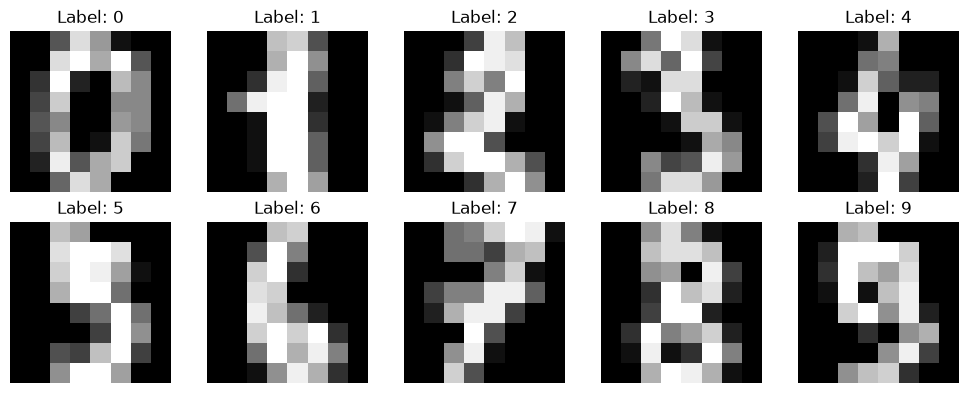

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()

X = digits.data
y = digits.target

print("Feature matrix:", X.shape)
print("Image array:", digits.images.shape)
print("Classes:", np.unique(y))
print("Pixel range:", X.min(), "to", X.max())

# Display a few images and their labels
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for ax, image, label in zip(
    axes.flat, digits.images[:10], y[:10]
):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Reserve the test set before model experiments
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic_Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

for name, model in models.items():
    results = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True, scoring="accuracy")
    print(f"\n{name}")
    print(
        f"Mean training accuracy: "
        f"{results['train_score'].mean():.3f}"
    )
    print(
        "Validation scores:",
        results["test_score"].round(3),
    )
    print(
        f"Mean validation accuracy: "
        f"{results['test_score'].mean():.3f}"
    )
    print(
        f"Standard deviation: "
        f"{results['test_score'].std():.3f}"
    )


Baseline
Mean training accuracy: 0.102
Validation scores: [0.101 0.101 0.101 0.101 0.101]
Mean validation accuracy: 0.101
Standard deviation: 0.000

Logistic_Regression
Mean training accuracy: 1.000
Validation scores: [0.958 0.969 0.972 0.962 0.979]
Mean validation accuracy: 0.968
Standard deviation: 0.007

KNN
Mean training accuracy: 0.984
Validation scores: [0.972 0.983 0.986 0.958 0.979]
Mean validation accuracy: 0.976
Standard deviation: 0.010
